# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Ejercicio 1: Diferencias entre LabelEncoder y OneHotEncoder

# LabelEncoder: convierte cada categoría en UN número dentro de UNA sola columna
print("LabelEncoder (sex -> sex_label):")
print(data[['sex', 'sex_label']].head())

# Ver qué número le tocó a cada categoría
print("\nEquivalencias:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

# OneHotEncoder: crea UNA columna NUEVA por cada categoría, con 1 (sí) o 0 (no)
print("\nOneHotEncoder (embarked -> columnas nuevas):")
print(data[['embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head())

# Comparar cuántas columnas genera cada método
print("\nColumnas que genera LabelEncoder:", 1)
print("Columnas que genera OneHotEncoder:", onehot_encoder.shape[1])

LabelEncoder (sex -> sex_label):
      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1

Equivalencias: {'female': 0, 'male': 1}

OneHotEncoder (embarked -> columnas nuevas):
  embarked  embarked_C  embarked_Q  embarked_S
0        S       False       False        True
1        C        True       False       False
2        S       False       False        True
3        S       False       False        True
4        S       False       False        True

Columnas que genera LabelEncoder: 1
Columnas que genera OneHotEncoder: 3


LabelEncoder convierte cada categoría en un número dentro de la misma columna (female=0, male=1). Es simple y no agrega columnas, pero los números pueden hacer que el modelo crea que existe un orden o jerarquía entre categorías. OneHotEncoder crea una columna por categoría con valores 0 o 1 (embarked_C, embarked_Q, embarked_S). Así no inventa un orden, pero agrega más columnas al conjunto de datos.

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

Antes:
 sex
female    314
male      577
Name: count, dtype: int64

Después:
 sex_label
0    314
1    577
Name: count, dtype: int64


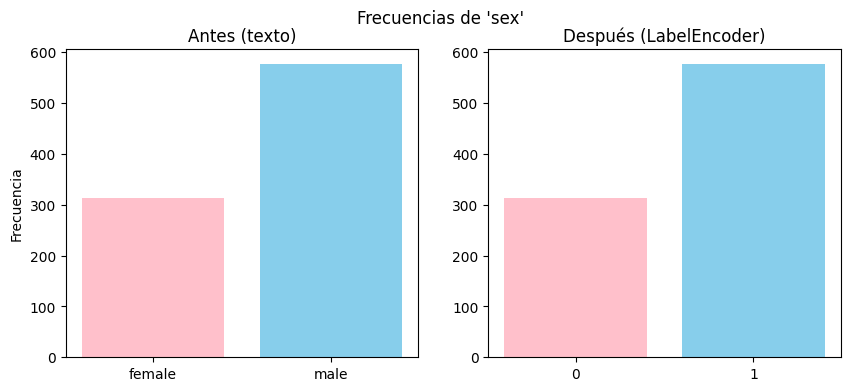

In [9]:
# Ejercicio 2: Frecuencias de 'sex' antes y después de LabelEncoder
import matplotlib.pyplot as plt

# Contar cuántas veces aparece cada valor
antes = data['sex'].value_counts().sort_index()          # female, male
despues = data['sex_label'].value_counts().sort_index()  # 0, 1

print("Antes:\n", antes)
print("\nDespués:\n", despues)

# Crear dos gráficas, una al lado de la otra
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].bar(antes.index, antes.values, color=['pink', 'skyblue'])
ax[0].set_title("Antes (texto)")
ax[0].set_ylabel("Frecuencia")

ax[1].bar(despues.index.astype(str), despues.values, color=['pink', 'skyblue'])
ax[1].set_title("Después (LabelEncoder)")

plt.suptitle("Frecuencias de 'sex'")
plt.show()

Las frecuencias son idénticas antes y después de la codificación (577 hombres y 314 mujeres). LabelEncoder solo reemplazó el texto por números (female=0, male=1) sin cambiar la información. Por eso las barras tienen la misma altura.

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:
# Ejercicio 3: OneHotEncoder en la columna 'class'

# Crear el codificador (sparse_output=False para obtener una tabla normal)
ohe = OneHotEncoder(sparse_output=False)

# Ajustar y transformar (se usa doble corchete porque espera una tabla)
class_ohe = ohe.fit_transform(data[['class']])

# Convertir el resultado en DataFrame con nombres de columnas
class_ohe_df = pd.DataFrame(class_ohe, columns=ohe.get_feature_names_out(['class']))

# Unirlo al conjunto original
data = pd.concat([data, class_ohe_df], axis=1)

print("OneHotEncoder en 'class':")
print(data[['class', 'class_First', 'class_Second', 'class_Third']].head())

# Comparación: cómo quedaría con LabelEncoder
le_class = LabelEncoder()
print("\nCon LabelEncoder sería:")
print(pd.DataFrame({'class': data['class'],
                    'class_label': le_class.fit_transform(data['class'])}).head())

OneHotEncoder en 'class':
   class  class_First  class_Second  class_Third
0  Third          0.0           0.0          1.0
1  First          1.0           0.0          0.0
2  Third          0.0           0.0          1.0
3  First          1.0           0.0          0.0
4  Third          0.0           0.0          1.0

Con LabelEncoder sería:
   class  class_label
0  Third            2
1  First            0
2  Third            2
3  First            0
4  Third            2


OneHotEncoder creó 3 columnas (class_First, class_Second, class_Third), donde un 1 indica la clase del pasajero. La ventaja frente a LabelEncoder es que no asigna números como 0, 1 y 2, que el modelo podría interpretar como cantidades (por ejemplo, que “Third” vale el doble que “Second”). Con One-Hot todas las categorías se tratan por igual y no hay distancias falsas entre ellas.

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [12]:
# Ejercicio 4: ¿Qué codificación elegir para un modelo?

# 1) ¿Cuántas categorías tiene cada columna?
print("Categorías únicas por columna:")
print(data[categorical_cols].nunique())

# 2) Elegir la codificación según el tipo de variable:
#    - 'sex' tiene solo 2 valores -> LabelEncoder basta (0/1, no hay orden falso)
#    - 'embarked' y 'class' tienen 3 valores -> One-Hot para evitar orden falso
columnas_modelo = ['sex_label',
                   'embarked_C', 'embarked_Q', 'embarked_S',
                   'class_First', 'class_Second', 'class_Third']

X = data[columnas_modelo].astype(int)  # Convertir True/False a 1/0

print("\nDatos listos para un modelo:")
print(X.head())

# 3) Comprobar que todo sea numérico
print("\nTipos de datos:")
print(X.dtypes)

Categorías únicas por columna:
sex         2
embarked    3
class       3
dtype: int64

Datos listos para un modelo:
   sex_label  embarked_C  embarked_Q  embarked_S  class_First  class_Second  \
0          1           0           0           1            0             0   
1          0           1           0           0            1             0   
2          0           0           0           1            0             0   
3          0           0           0           1            1             0   
4          1           0           0           1            0             0   

   class_Third  
0            1  
1            0  
2            1  
3            0  
4            1  

Tipos de datos:
sex_label       int64
embarked_C      int64
embarked_Q      int64
embarked_S      int64
class_First     int64
class_Second    int64
class_Third     int64
dtype: object


Para variables nominales (sin orden), como embarked, elegiría One-Hot Encoding, porque no inventa una jerarquía entre categorías. Para variables binarias, como sex, LabelEncoder es suficiente, ya que 0/1 no crea un orden engañoso y no agrega columnas extra. Si una variable fuera ordinal (con orden real), LabelEncoder u OrdinalEncoder podrían ser útiles. Aun así, en class preferí One-Hot para que el modelo no asuma distancias iguales entre clases. La desventaja de One-Hot es que, con muchas categorías, genera demasiadas columnas.